In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/bank-full.csv', sep=';')

print("Dataset shape:", df.shape)
print("\nFirst 10 records:")
display(df.head(10))

print("\nColumn data types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe(include='all').T)

FileNotFoundError: [Errno 2] No such file or directory: '/content/bank-full.csv'

In [4]:
df = pd.read_csv('/content/bank-full.csv', sep=';')

In [5]:
print("Dataset dimensions:", df.shape)

print("\nFirst 10 records:")
display(df.head(10))

print("\nColumn data types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe(include='all').T)

Dataset dimensions: (45211, 17)

First 10 records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no



Column data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget column distribution:")
print(df['y'].value_counts())

print("\nTarget percentages:")
print(df['y'].value_counts(normalize=True).mul(100).round(2))

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows: 0

Target column distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [7]:
print("Numerical columns:")
print(df.select_dtypes(include='number').columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns.tolist())

print("\nTarget column:", 'y')

Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Target column: y


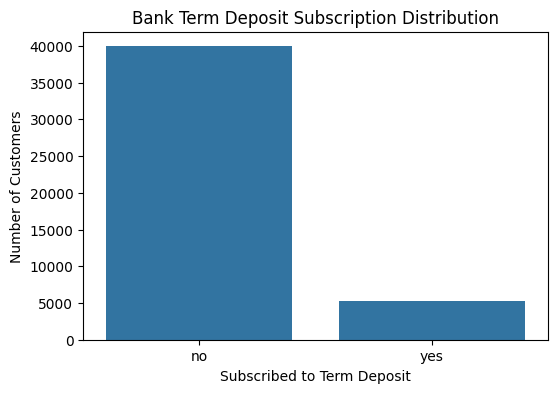

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='y')

plt.title('Bank Term Deposit Subscription Distribution')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

plt.show()

Subscription percentage by job:


y,no,yes
job,,
student,71.32,28.68
retired,77.21,22.79
unemployed,84.50,15.50
management,86.24,13.76
admin.,87.80,12.20
self-employed,88.16,11.84
unknown,88.19,11.81
technician,88.94,11.06
services,91.12,8.88


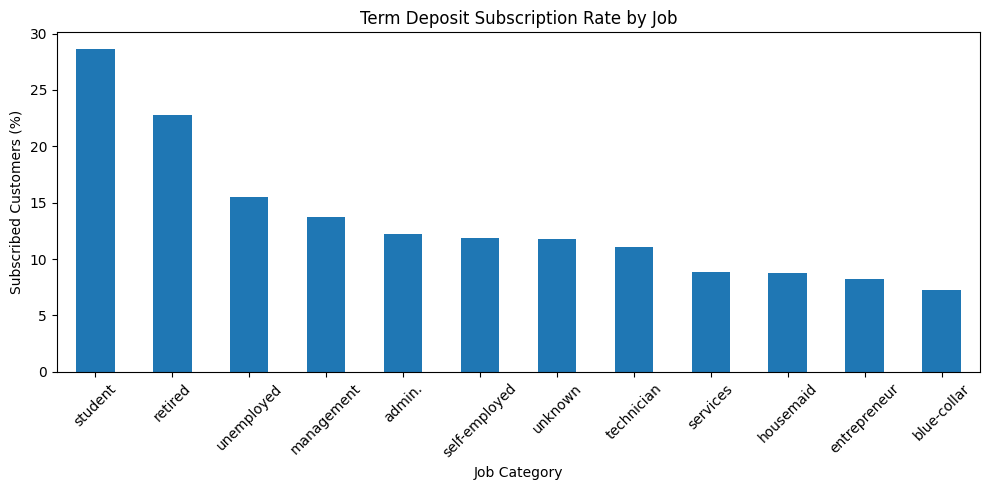

In [9]:
job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription = job_subscription.sort_values(
    by='yes',
    ascending=False
)

print("Subscription percentage by job:")
display(job_subscription.round(2))

job_subscription['yes'].plot(kind='bar', figsize=(10, 5))

plt.title('Term Deposit Subscription Rate by Job')
plt.xlabel('Job Category')
plt.ylabel('Subscribed Customers (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Subscription percentage by education:


y,no,yes
education,,
primary,91.37,8.63
secondary,89.44,10.56
tertiary,84.99,15.01
unknown,86.43,13.57


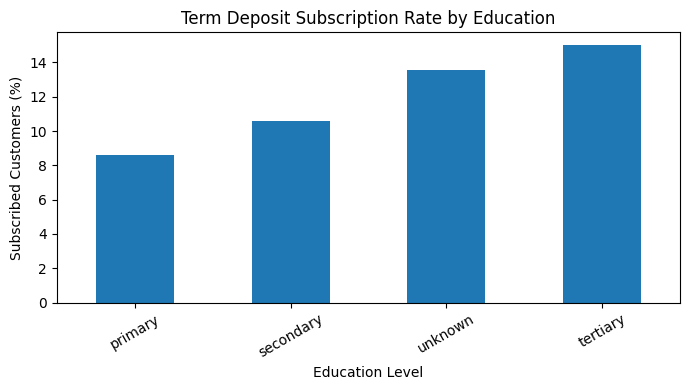

In [10]:
education_subscription = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

print("Subscription percentage by education:")
display(education_subscription.round(2))

education_subscription['yes'].sort_values().plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Term Deposit Subscription Rate by Education')
plt.xlabel('Education Level')
plt.ylabel('Subscribed Customers (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

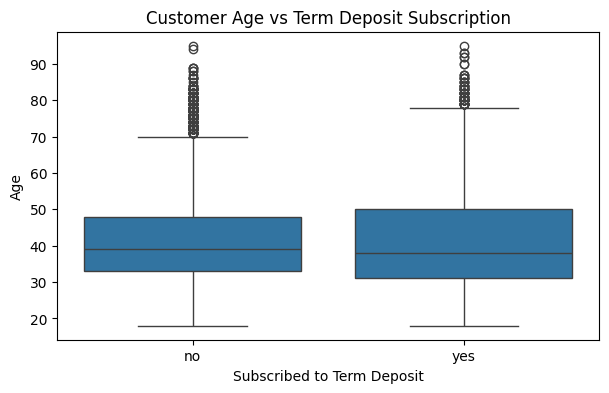

In [11]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x='y', y='age')

plt.title('Customer Age vs Term Deposit Subscription')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Age')

plt.show()

In [12]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Separate target from input features
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})

print("Feature dataset shape:", X.shape)
print("\nTarget dataset shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Feature dataset shape: (45211, 15)

Target dataset shape: (45211,)

Target values:
y
0    39922
1     5289
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (36168, 15)
Testing features: (9043, 15)

Training target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

# Preprocess each type of column
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# Fit only on training data, then transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (36168, 50)
Processed testing data shape: (9043, 50)


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the four classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully
Random Forest trained successfully


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8933,0.6632,0.1786,0.2815
1,Decision Tree,0.8309,0.2982,0.3289,0.3128
2,KNN,0.8874,0.5529,0.1975,0.2911
3,Random Forest,0.8954,0.6373,0.2457,0.3547


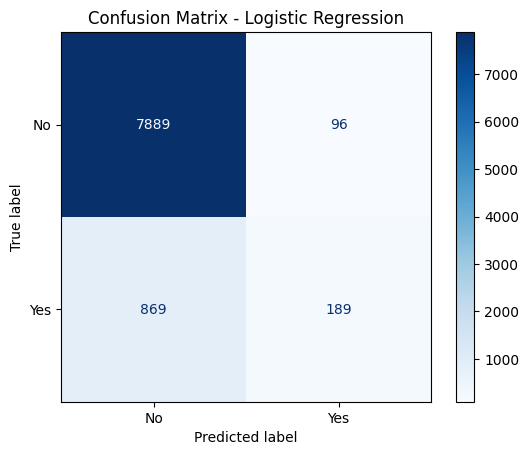

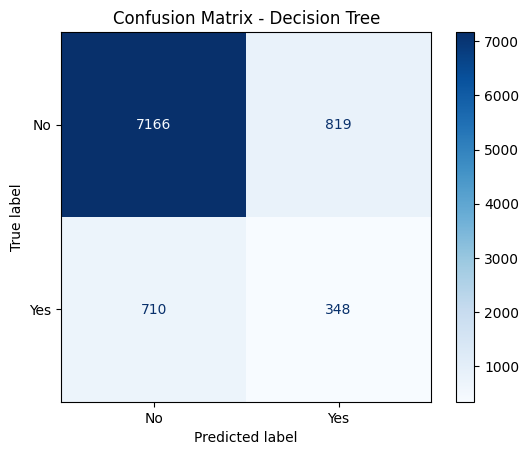

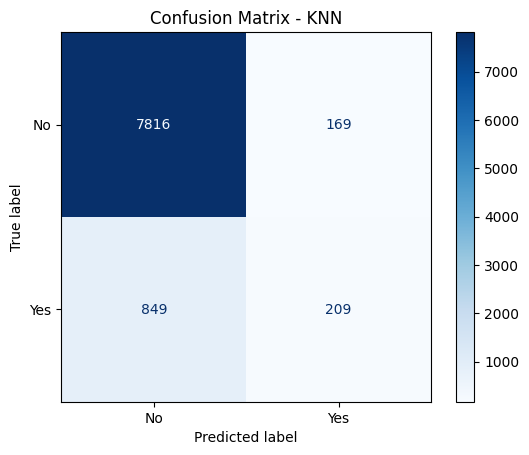

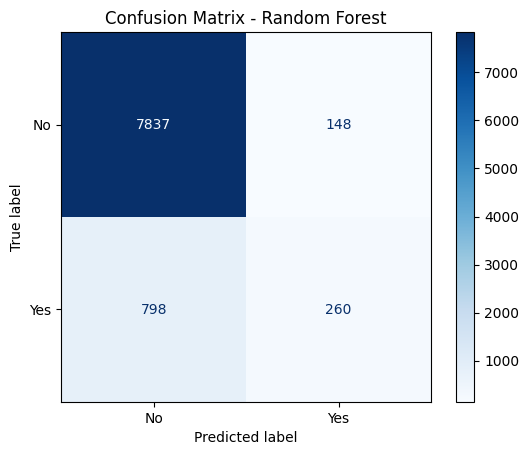

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No', 'Yes']
    )

    display.plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

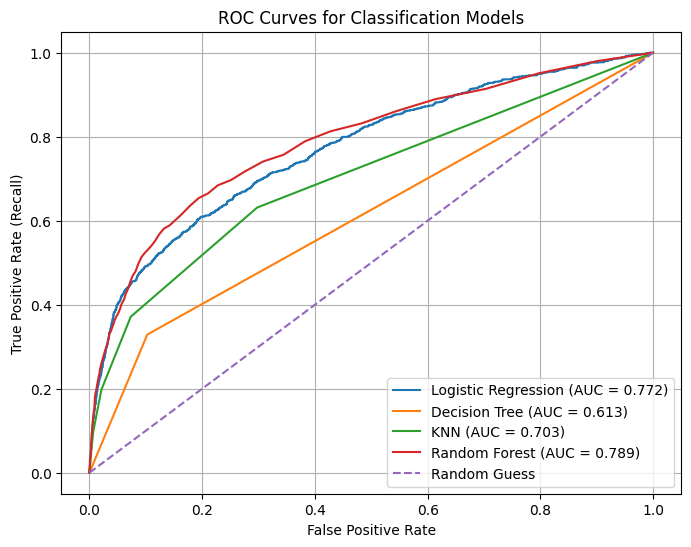

In [18]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')
plt.title('ROC Curves for Classification Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
from IPython.display import display as show_table

show_table(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
1,Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888


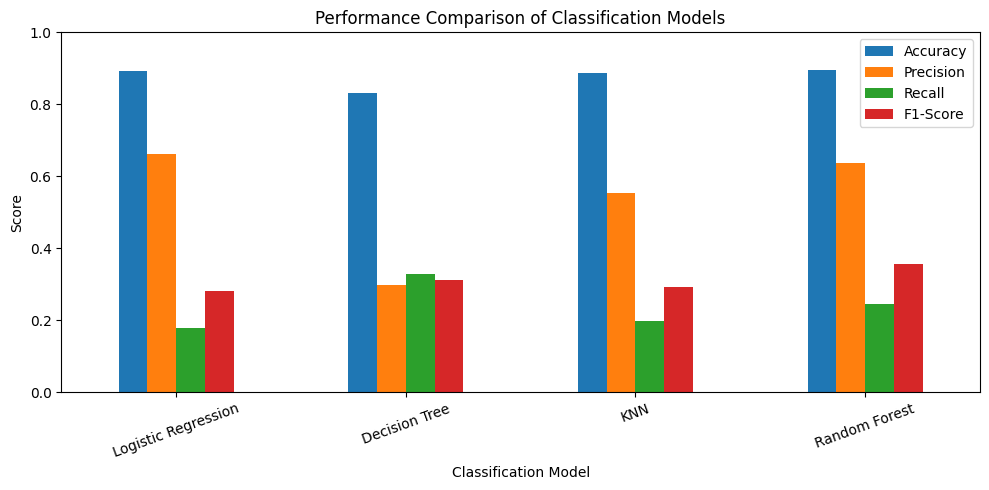

In [21]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(kind='bar', figsize=(10, 5))

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Model')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [22]:
show_table(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
1,Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888


The bank can use the prediction model to help prioritize customers for marketing campaigns, while validating the model before real-world deployment.



The bank should consider recall and precision alongside accuracy so it can balance finding potential subscribers with the cost of contacting customers who do not subscribe.

The models have relatively low recall, meaning they miss many customers who actually subscribe.



Customer behavior and campaign outcomes may change over time, so the model should be evaluated regularly using newer data

Conclusion:
This case study compared Logistic Regression, Decision Tree, KNN, and Random Forest for predicting bank term-deposit subscriptions. Random Forest achieved the highest accuracy of 89.54%, F1-score of 0.3547, and ROC-AUC of 0.7888. Decision Tree achieved the highest recall of 32.89%. The results show that accuracy alone is insufficient for this imbalanced dataset. The bank should consider multiple evaluation metrics when selecting a model for marketing campaigns.
